In [36]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project folders
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

# Load cleaned datasets
matches = pd.read_csv(PROCESSED_DIR / "matches_cleaned.csv")
deliveries = pd.read_csv(PROCESSED_DIR / "deliveries_cleaned.csv")
points_table = pd.read_csv(PROCESSED_DIR / "points_table_cleaned.csv")

print("All datasets loaded successfully!")



All datasets loaded successfully!


In [37]:
print("Matches:", matches.shape)
print("Deliveries:", deliveries.shape)
print("Points Table:", points_table.shape)

Matches: (48, 17)
Deliveries: (26118, 20)
Points Table: (10, 11)


,bowler,Total_Wickets
0,A Zampa,585
1,Kuldeep Yadav,575
2,JJ Bumrah,573
3,JR Hazlewood,569
4,RA Jadeja,565
5,TA Boult,563
6,MA Starc,561
7,MJ Santner,561
8,PJ Cummins,552
9,KA Maharaj,542


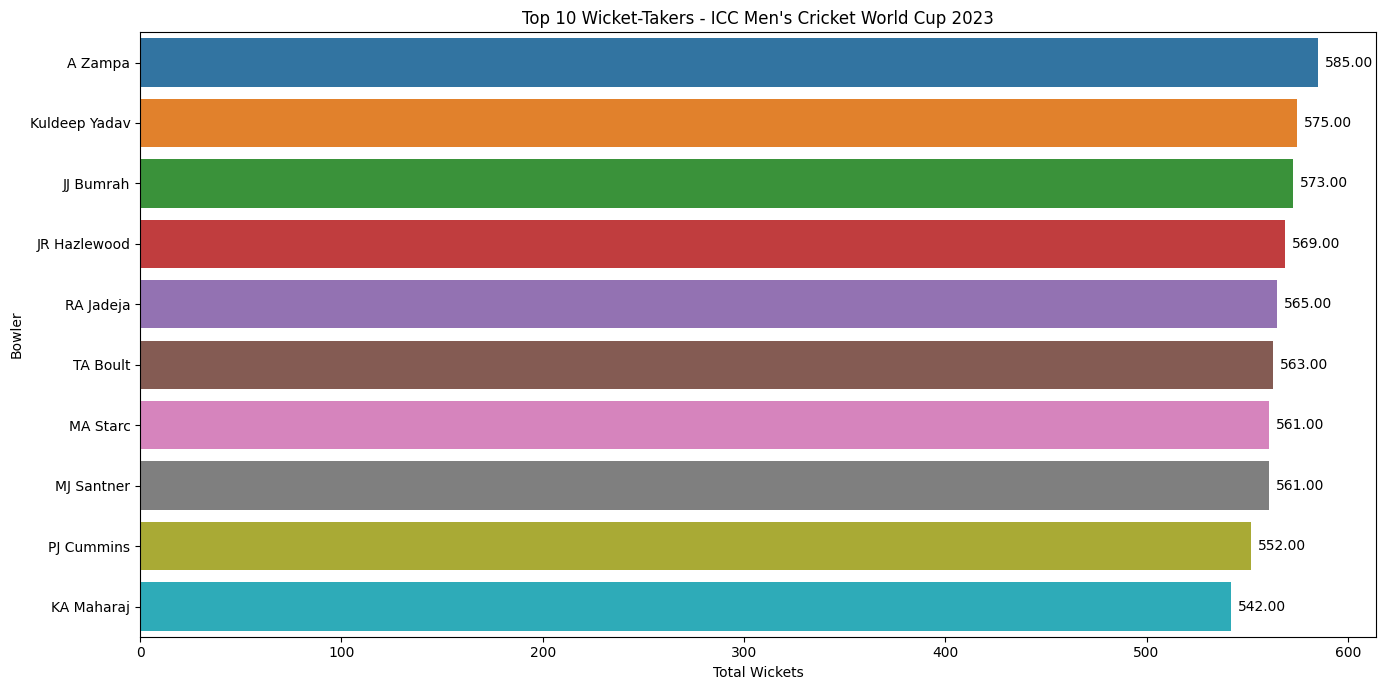

In [38]:
# Q1. Who were the top 10 wicket-takers in the tournament?

bowler_wickets = deliveries[
    deliveries["wicket_type"].notna()
    & (~deliveries["wicket_type"].isin(["run out", "retired hurt", "obstructing the field"]))
]

# count wicket taken by each bowler
wicket_stats = (
    bowler_wickets.groupby("bowler").size().reset_index(name="Total_Wickets")
)

wicket_stats = wicket_stats.sort_values(
    by="Total_Wickets",
    ascending=False
).reset_index(drop=True)

display(wicket_stats.head(10))

# select top 10 wicket-takers

top_10_bowlers = wicket_stats.head(10).sort_values(
    by="Total_Wickets",
    ascending=False
)

plt.figure(figsize=(14,7))

ax = sns.barplot(
    data=top_10_bowlers,
    x="Total_Wickets",
    y="bowler",
    hue="bowler"
)

# add data labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_width():.2f}" for bar in container],
        padding=5,
        fontsize=10
    )
    
plt.title("Top 10 Wicket-Takers - ICC Men's Cricket World Cup 2023")
plt.xlabel("Total Wickets")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()

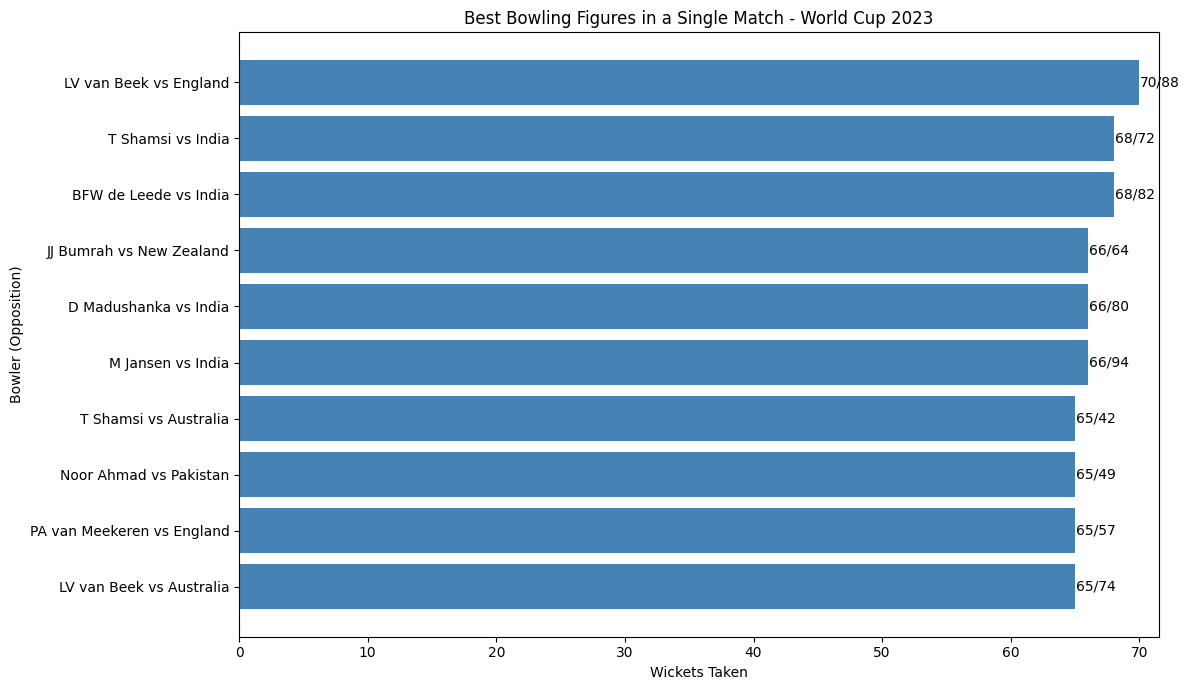

,match_id,bowler,bowling_team,batting_team,Bowling_Figures,Wickets,Runs_Conceded
0,24,LV van Beek,Netherlands,Australia,65/74,65,74.0
1,40,PA van Meekeren,Netherlands,England,65/57,65,57.0
2,22,Noor Ahmad,Afghanistan,Pakistan,65/49,65,49.0
3,47,T Shamsi,South Africa,Australia,65/42,65,42.0
4,37,M Jansen,South Africa,India,66/94,66,94.0
5,33,D Madushanka,Sri Lanka,India,66/80,66,80.0
6,46,JJ Bumrah,India,New Zealand,66/64,66,64.0
7,45,BFW de Leede,Netherlands,India,68/82,68,82.0
8,37,T Shamsi,South Africa,India,68/72,68,72.0
9,40,LV van Beek,Netherlands,England,70/88,70,88.0


In [39]:

import pandas as pd
import matplotlib.pyplot as plt

# Q2. Which bowlers recorded the best bowling figures in a single match?

# Wicket types NOT credited to the bowler
non_bowler_wickets = [
    "run out",
    "retired hurt",
    "retired out",
    "obstructing the field",
    "hit the ball twice"
]

# Make sure numeric columns are numeric
numeric_cols = ["runs_off_bat", "wides", "noballs"]

for col in numeric_cols:
    deliveries[col] = pd.to_numeric(
        deliveries[col], errors="coerce"
    ).fillna(0)

# Calculate runs conceded by the bowler
# Byes, leg-byes and penalty runs are not charged to the bowler
deliveries["bowler_runs"] = (
    deliveries["runs_off_bat"]
    + deliveries["wides"]
    + deliveries["noballs"]
)

# Clean wicket types
wicket_type = (
    deliveries["wicket_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Count only wickets credited to the bowler
deliveries["bowler_wicket"] = (
    wicket_type.notna()
    & ~wicket_type.isin(non_bowler_wickets)
).astype(int)

# Calculate bowling figures for each match
bowling_figures = (
    deliveries.groupby(
        ["match_id", "bowler", "bowling_team", "batting_team"],
        dropna=False
    )
    .agg(
        Wickets=("bowler_wicket", "sum"),
        Runs_Conceded=("bowler_runs", "sum")
    )
    .reset_index()
)

# Format bowling figures as wickets/runs
bowling_figures["Bowling_Figures"] = (
    bowling_figures["Wickets"].astype(int).astype(str)
    + "/"
    + bowling_figures["Runs_Conceded"].astype(int).astype(str)
)

# Select top 10: most wickets, then fewest runs conceded
top_10_figures = (
    bowling_figures
    .sort_values(
        by=["Wickets", "Runs_Conceded"],
        ascending=[False, True]
    )
    .head(10)
    .copy()
)

# Create readable labels
top_10_figures["Bowler_Match"] = (
    top_10_figures["bowler"].astype(str)
    + " vs "
    + top_10_figures["batting_team"].astype(str)
)

# Reverse order for horizontal chart
top_10_figures = top_10_figures.sort_values(
    by=["Wickets", "Runs_Conceded"],
    ascending=[True, False]
)

# Matplotlib horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_10_figures["Bowler_Match"],
    top_10_figures["Wickets"],
    color="steelblue"
)

# Add bowling figures as labels
for bar, (_, row) in zip(bars, top_10_figures.iterrows()):
    ax.text(
        bar.get_width() + 0.08,
        bar.get_y() + bar.get_height() / 2,
        row["Bowling_Figures"],
        va="center",
        fontsize=10
    )

ax.set_title(
    "Best Bowling Figures in a Single Match - World Cup 2023"
)
ax.set_xlabel("Wickets Taken")
ax.set_ylabel("Bowler (Opposition)")
ax.set_xlim(0, top_10_figures["Wickets"].max() + 1.5)

plt.tight_layout()
plt.show()

# Display results
display(
    top_10_figures[
        [
            "match_id",
            "bowler",
            "bowling_team",
            "batting_team",
            "Bowling_Figures",
            "Wickets",
            "Runs_Conceded"
        ]
    ].reset_index(drop=True)
)


,bowler,Runs_Conceded,Legal_Balls,Overs_Bowled,Economy_Rate
0,R Ashwin,34.0,60,10.000000,3.40
1,JJ Bumrah,373.0,551,91.833333,4.06
2,Mohammad Nabi,254.0,369,61.500000,4.13
3,KA Maharaj,370.0,534,89.000000,4.16
4,RA Jadeja,398.0,561,93.500000,4.26
5,Kuldeep Yadav,424.0,571,95.166667,4.46
6,Rashid Khan,388.0,519,86.500000,4.49
7,AK Markram,85.0,111,18.500000,4.59
8,Noor Ahmad,182.0,228,38.000000,4.79
9,TM Head,101.0,126,21.000000,4.81


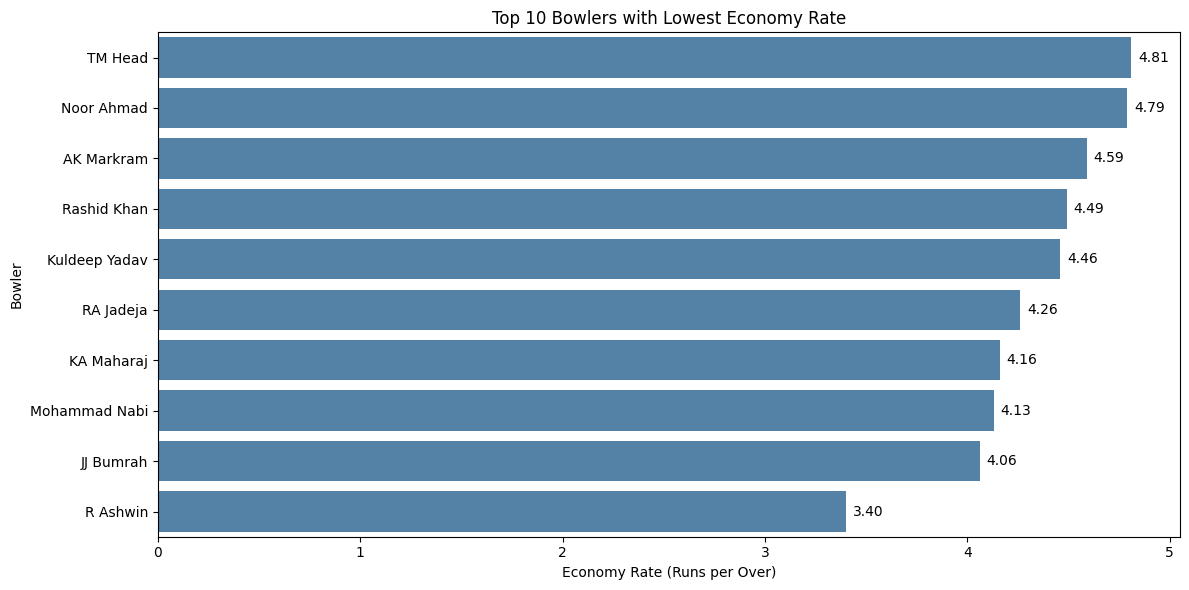

In [40]:
# Q3 Which bowlers achieved the lowest bowling economy rates, subject to a minimum overs-bowled threshold?

# Calculate runs conceded by each bowler
deliveries["bowler_runs"] = (
    deliveries["runs_off_bat"] + deliveries["wides"].fillna(0) + deliveries["noballs"].fillna(0)
)

# Legal deliveries: exclude wides and no-balls
deliveries["legal_ball"] = (
    deliveries["wides"].fillna(0).eq(0) & deliveries["noballs"].fillna(0).eq(0)
)

# Aggregate bowling statistics
bowling_economy = deliveries.groupby("bowler").agg(
    Runs_Conceded = ("bowler_runs", "sum"),
    Legal_Balls = ("legal_ball", "sum")
).reset_index()

# calculation overs and economy rate
bowling_economy["Overs_Bowled"] = (
    bowling_economy["Legal_Balls"] / 6
)

bowling_economy["Economy_Rate"] = (
    bowling_economy["Runs_Conceded"] / bowling_economy["Overs_Bowled"]
).round(2)

# apply minimum 10 overs threshold
MIN_OVERS = 10

qualified_bowlers = bowling_economy[
    bowling_economy["Legal_Balls"] >= MIN_OVERS * 6
].copy()

# Lowest economy rate first
qualified_bowlers = qualified_bowlers.sort_values(
    by="Economy_Rate",
    ascending=True
).reset_index(drop=True)

# Display top 10 bowlers with lowest economy rates
display(qualified_bowlers.head(10))


top_10_economy = qualified_bowlers.head(10).sort_values(
    by="Economy_Rate",
    ascending=False
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=top_10_economy,
    x="Economy_Rate",
    y="bowler",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_width():.2f}" for bar in container],
        padding=5,
        fontsize=10
    )
    
plt.title("Top 10 Bowlers with Lowest Economy Rate")
plt.xlabel("Economy Rate (Runs per Over)")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()

,bowler,Legal_Balls,Total_Wickets,Overs_Bowled,Bowling_Strike_Rate
0,C Karunaratne,72,80,12.000000,0.90
1,M Pathirana,114,126,19.000000,0.90
2,MR Marsh,78,83,13.000000,0.94
3,M Jansen,414,438,69.000000,0.95
4,L Ngidi,363,377,60.500000,0.96
5,MA Starc,522,545,87.000000,0.96
6,SM Curran,104,108,17.333333,0.96
7,LV van Beek,425,438,70.833333,0.97
8,Noor Ahmad,228,235,38.000000,0.97
9,DM de Silva,150,154,25.000000,0.97


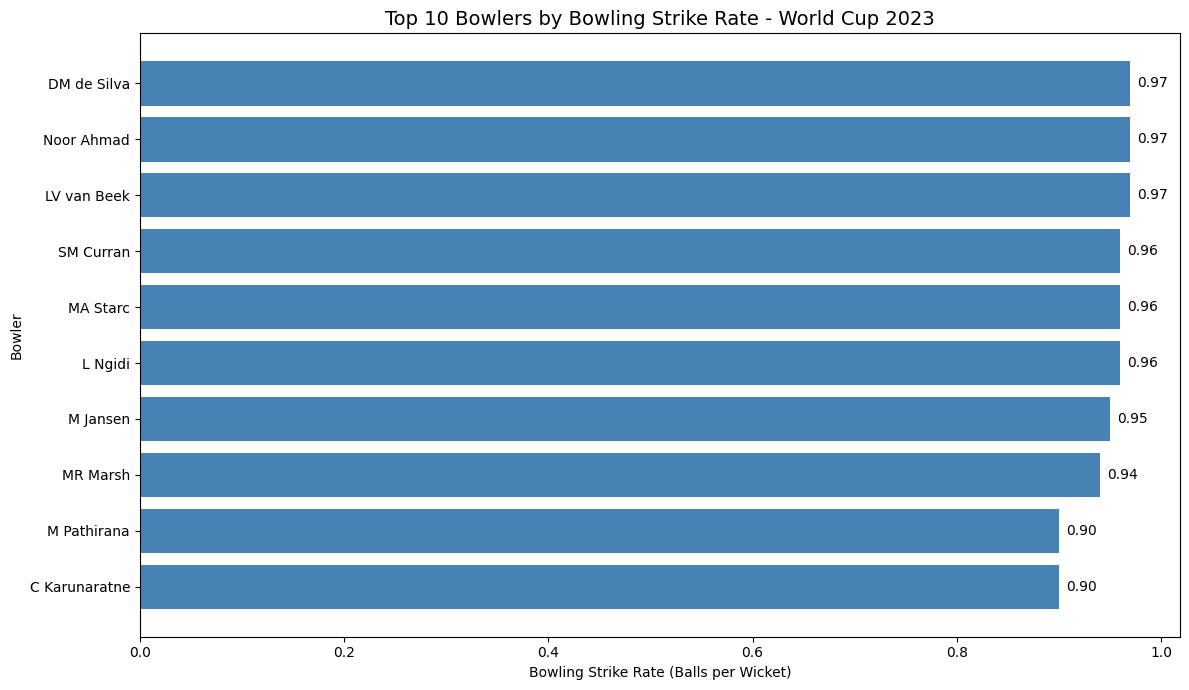

In [41]:
# Q4. Which bowlers recorded the best bowling strike rates?

# Wicket types not creadited to the bowler
non_bowler_wickets = [
    "caught",
    "bowled",
    "lbw",
    "run out",
    "caught and bowled",
    "stumped"
    "retired hurt"
]

# Identify legal deliveries
deliveries["legal_ball"] = (
    deliveries["wides"].fillna(0).eq(0) & deliveries["noballs"].fillna(0).eq(0)
)

# Identify wickets creadited to the bowler

deliveries["bowler_wicket"] = (
    deliveries["wicket_type"].notna()
    & ~deliveries["wicket_type"].str.lower().isin(non_bowler_wickets)
).astype(int)

# calculate total legal balls and wickets per bowler
bowling_strike_rate = deliveries.groupby("bowler").agg(
    Legal_Balls = ("legal_ball", "sum"),
    Total_Wickets = ("bowler_wicket", "sum")
).reset_index()

# Remove bowlers with zero wickets
bowling_strike_rate = bowling_strike_rate[
    bowling_strike_rate["Total_Wickets"] > 0
].copy()

# Apply minimum 10 overs threshold
bowling_strike_rate = bowling_strike_rate[
    bowling_strike_rate["Legal_Balls"] >= 60
].copy()

# Calculate bowlling strike rate
bowling_strike_rate["Overs_Bowled"] = (
    bowling_strike_rate["Legal_Balls"] / 6
)

bowling_strike_rate["Bowling_Strike_Rate"] = (
    bowling_strike_rate["Legal_Balls"] / bowling_strike_rate["Total_Wickets"]
).round(2)

bowling_strike_rate = bowling_strike_rate.sort_values(
    by="Bowling_Strike_Rate", ascending=True
).reset_index(drop=True)


# Display top 10 bowlers
display(bowling_strike_rate.head(10))


top_10_strike_rate = bowling_strike_rate.head(10).sort_values(
    by="Bowling_Strike_Rate",
    ascending=True
)

plt.figure(figsize=(12,7))

bars =  plt.barh(
    top_10_strike_rate["bowler"],
    top_10_strike_rate["Bowling_Strike_Rate"],
    color="steelblue"
    
)

# add data labels 
plt.bar_label(
    bars,
    fmt="%.2f",
    padding=5,
    fontsize=10
)

plt.title(
    "Top 10 Bowlers by Bowling Strike Rate - World Cup 2023",
    fontsize=14
)
plt.xlabel("Bowling Strike Rate (Balls per Wicket)")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()

,Team,Total_Wickets
0,Australia,3084
1,India,2840
2,New Zealand,2753
3,South Africa,2680
4,Netherlands,2563
5,Pakistan,2551
6,Afghanistan,2457
7,Bangladesh,2432
8,England,2383
9,Sri Lanka,2336


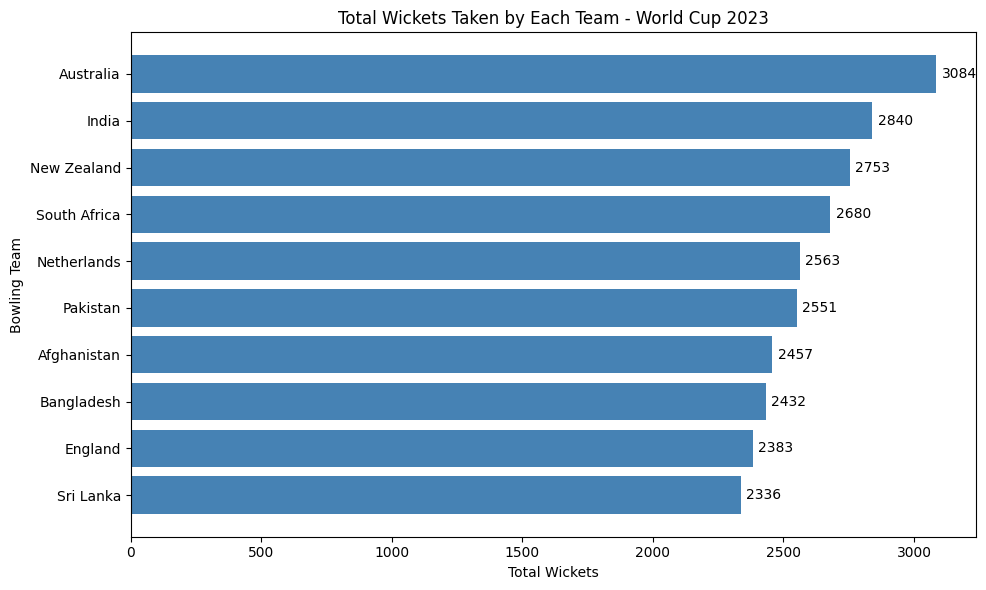

In [42]:
# Q5. Which teams took the highest total number of wickets?


# Exclude dismissals not credited to the bowler
non_bowler_wickets = [
    "run out",
    "retired hurt",
    "retired out",
    "obstructing the field",
    "hit the ball twice"
]

wicket_type = (
    deliveries["wicket_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Count only wickets credited to bowlers
deliveries["bowler_wicket"] = (
    wicket_type.notna()
    & ~wicket_type.isin(non_bowler_wickets)
).astype(int)

# Calculate total wickets taken by each bowling team
team_wickets = (
    deliveries.groupby("bowling_team")["bowler_wicket"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

team_wickets.columns = ["Team", "Total_Wickets"]

display(team_wickets)

# Plot the results
plt.figure(figsize=(10, 6))

bars = plt.barh(
    team_wickets["Team"],
    team_wickets["Total_Wickets"],
    color="steelblue"
)

plt.bar_label(bars, padding=4)
plt.title("Total Wickets Taken by Each Team - World Cup 2023")
plt.xlabel("Total Wickets")
plt.ylabel("Bowling Team")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

,Phase,Total_Wickets
0,Powerplay,5939
1,Middle Overs,16395
2,Death Overs,3178


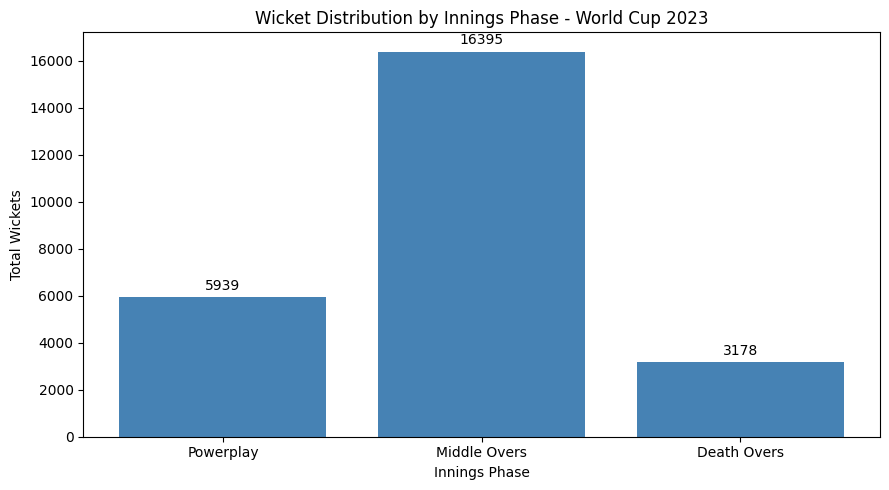

In [43]:
# Q6. How were wickets distributed across the Powerplay, middle overs, and death overs?

df = deliveries.copy()

# Extract over number from ball column 
df["Over"] = pd.to_numeric(
    df["ball"].astype(str).str.split(".").str[0],
    errors="coerce"
)

# Identify deliveries containing a wicket
df["wicket_type"] = (
    df["wicket_type"].astype("string").str.strip().str.lower()
)

df["Wicket"] = (
    df["wicket_type"].notna()
    & ~df["wicket_type"].isin(["retired hurt"])
).astype(int)

# Classify innings phases
df["Phase"] = pd.cut(
    df["Over"],
    bins=[0, 10, 40, 50],
    labels=["Powerplay", "Middle Overs", "Death Overs"]
)

# Count wickets in each phase
phase_wickets = (
    df.groupby("Phase", observed=False)["Wicket"]
    .sum()
    .reset_index()
)

phase_wickets.columns = ["Phase", "Total_Wickets"]

display(phase_wickets)

# Visualize with Matplotlib
plt.figure(figsize=(9, 5))

bars = plt.bar(
    phase_wickets["Phase"].astype(str),
    phase_wickets["Total_Wickets"],
    color="steelblue"
)

plt.bar_label(bars, padding=3)
plt.title("Wicket Distribution by Innings Phase - World Cup 2023")
plt.xlabel("Innings Phase")
plt.ylabel("Total Wickets")
plt.tight_layout()
plt.show()

In [44]:


matches = pd.read_csv("../data/processed/matches_cleaned.csv")
deliveries = pd.read_csv("../data/processed/deliveries_cleaned.csv")
points = pd.read_csv("../data/processed/points_table_cleaned.csv")

print("Matches CSV:", len(matches))
print("Deliveries CSV:", len(deliveries))
print("Points Table CSV:", len(points))

Matches CSV: 48
Deliveries CSV: 26118
Points Table CSV: 10


In [45]:
deliveries["wicket_type"].value_counts()

wicket_type
No Wicket            25389
caught                 448
bowled                 141
lbw                     76
run out                 38
caught and bowled       14
stumped                 11
retired hurt             1
Name: count, dtype: int64

In [46]:
matches.shape[1]
deliveries.columns.tolist()

['match_id',
 'season',
 'start_date',
 'venue',
 'innings',
 'ball',
 'batting_team',
 'bowling_team',
 'striker',
 'non_striker',
 'bowler',
 'runs_off_bat',
 'extras',
 'wides',
 'noballs',
 'byes',
 'legbyes',
 'penalty',
 'wicket_type',
 'player_dismissed']